# NB09: Optimization, Stochastic, and Computation Public API Walkthrough

This notebook covers the advanced system capabilities. You will learn:

1. Explicit model-runner calibration with differential evolution
2. Local finite-difference elasticities and uncertainty quantification (Sobol indices are introduced only)
3. Stochastic process modeling and Monte Carlo methods
4. GPU acceleration and computational performance utilities

**Prerequisites:** NB01-NB08.

**Theory Reference:** `docs/source/coertheory.md`, Section on differentiable
simulation and parameter optimization.

## Architecture Anchor

This notebook is aligned with `docs\source\architecture_overview.md` and the relevant theory/API pages under `docs\source`.
All computations below are intended to use actual RELIC functors, the actual simulator or orchestration layer, and real validation pathways rather than notebook-defined pseudo-process equations.


### Optimization and Uncertainty Quantification

For a differentiable fixed path $x^{n+1}=F_n(x^n,\theta)$, the parameter
sensitivity obeys

$$S_{n+1}=F_{n,x}S_n+F_{n,\theta},\qquad
S_0=\frac{\partial x^0}{\partial\theta}.$$

Every step's parameter dependence contributes. A single product of state
Jacobians times one local derivative is not the general trajectory gradient.
Events, clipping, adaptive decisions and topology changes need separate
contracts. A Functor holds bindings of its own ParameterManager by identity;
shared holders accumulate gradients in one theta. Local
`parameter_sensitivity` refuses these bindings; manager calibration uses
`get_trainable_parameters` for the shared gradient path.

The executable example uses differential evolution, an explicit model
runner and detached predictions. It does not demonstrate backpropagation
through the simulator or gradient-based optimization.

For reference, a first-order Sobol index is

$$S_i=\frac{\operatorname{Var}_{X_i}
[\mathbb{E}_{X_{\sim i}}(Y\mid X_i)]}{\operatorname{Var}(Y)}.$$

This notebook executes a local central-difference elasticity screen, not a
Sobol estimator; the global workflow belongs to NB20.


## Setup and Imports

Import the optimization framework, stochastic utilities, and
computation acceleration tools.

In [1]:
from __future__ import annotations

import asyncio
import os
import sys
import warnings
from pathlib import Path

if hasattr(asyncio, 'WindowsSelectorEventLoopPolicy'):
    asyncio.set_event_loop_policy(asyncio.WindowsSelectorEventLoopPolicy())

os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'

import matplotlib.pyplot as plt
import torch

warnings.filterwarnings(
    'ignore',
    message='The pynvml package is deprecated.*',
    category=FutureWarning,
    module='torch\\.cuda\\.__init__',
)
warnings.filterwarnings('ignore', category=torch.jit.TracerWarning)

DEFAULT_PROJECT_ROOT = Path(os.environ.get('RELIC_PROJECT_ROOT', Path.cwd())).resolve()


def locate_project_root() -> Path:
    candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents, DEFAULT_PROJECT_ROOT]
    for candidate in candidates:
        if (candidate / 'relic').is_dir() and (candidate / 'docs' / 'source' / 'architecture_overview.md').is_file():
            return candidate
    raise FileNotFoundError('Could not locate RELIC project root from the active notebook environment.')


PROJECT_ROOT = locate_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from relic.computation import healthcheck, select_device
from relic.computation.jit import maybe_compile
from relic.optimization import CalibrationConfig, CalibrationMethod, ParameterCalibrator, get_available_optimizers
from relic.optimization.calibration import CalibrationHooks, CalibrationEvent
from relic.parameters import get_global_manager
from relic.stochastic import EnsembleRunner, WeatherGenerator, get_available_distributions, get_available_samplers
from relic.stochastic.ensemble_runner import ExecutionConfig, ExecutionMode, StatisticType
from relic.stochastic.sde_solver import EulerMaruyamaSolver, SDEParameters
from relic.stochastic.validation import crps_score
from relic.stochastic.weather_generator import OrnsteinUhlenbeckTemperature, TemperatureParameters
from relic.scientific.biosphere.photosynthesis.farquhar import FarquharPhotosynthesis

DT_SECONDS = 1800.0
N_STEPS = 32


# References: synthetic tutorial forcing, not a fitted weather model.
# Mathematical expression: h=i*dt/3600; s=I(6<=h<=18)*sin(pi*clip((h-6)/12,0,1)).
#   PPFD=70+1400*max(s,0)^1.2; T=295+5.5*sin(2*pi*(h-5)/24).
#   f_w=clip(0.83+0.14*sin(2*pi*h/24+0.7),0.70,1.00).
# Parameter meanings: n_steps is sample count; dt is the sample interval.
# Units: dt [s], PPFD [umol photons m-2 s-1], T [K], f_w [1].
# Domain/constraints: a finite hand-built forcing sequence, not observations.
# Sign convention: PPFD is non-negative; water stress is an activity factor.
def build_forcing(n_steps: int = N_STEPS, dt: float = DT_SECONDS) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
    time_index = torch.arange(n_steps, dtype=torch.float32)
    hour = time_index * dt / 3600.0
    daylight = ((hour >= 6.0) & (hour <= 18.0)).float()
    phase = torch.pi * torch.clamp((hour - 6.0) / 12.0, 0.0, 1.0)
    solar = daylight * torch.sin(phase)
    par = 70.0 + 1400.0 * torch.pow(torch.clamp(solar, min=0.0), 1.2)
    temperature = 295.0 + 5.5 * torch.sin(2.0 * torch.pi * (hour - 5.0) / 24.0)
    water_stress = 0.83 + 0.14 * torch.sin(2.0 * torch.pi * hour / 24.0 + 0.7)
    water_stress = torch.clamp(water_stress, 0.70, 1.00)
    return time_index, par, temperature, water_stress


# References: Farquhar et al. (1980); FarquharPhotosynthesis input contract.
# Mathematical expression: assemble forcing tensors; no process law is duplicated.
# Parameter meanings: par is PPFD; co2_ppm is atmospheric CO2; water_stress is f_w.
# Units: T [K], PPFD [umol photons m-2 s-1], CO2 [umol mol-1], VPD [Pa],
#   LAI [m2 m-2]; stress/scaling factors [1].
# Domain/constraints: all required inputs, including leaf_area_index, are explicit.
# Sign convention: positive assimilation denotes CO2 uptake in the called process.
def build_photosynthesis_state(
    par: torch.Tensor,
    temperature: torch.Tensor,
    water_stress: torch.Tensor,
    co2_ppm: float = 410.0,
) -> dict:
    par_t = torch.as_tensor(par, dtype=torch.float32)
    temperature_t = torch.as_tensor(temperature, dtype=torch.float32)
    water_stress_t = torch.as_tensor(water_stress, dtype=torch.float32)
    co2_t = torch.full_like(par_t, float(co2_ppm))
    ones = torch.ones_like(par_t)
    return {
        'air_temperature': temperature_t,
        'atmospheric_co2_ppm': co2_t,
        'ppfd': par_t,
        'vcmax_scaling': ones,
        'jmax_scaling': ones,
        'water_stress_factor': water_stress_t,
        'temperature_stress_factor': ones,
        'ozone_stress_factor': ones,
        'vapor_pressure_deficit': torch.full_like(par_t, 1100.0),  # Pa (1.10 kPa)
        'leaf_area_index': torch.full_like(par_t, 3.00),
        'leaf_water_potential': torch.full_like(par_t, -0.30),
    }


def run_farquhar_series(
    vcmax25: float,
    jmax25: float,
    rd25: float,
    par_series: torch.Tensor,
    temperature_series: torch.Tensor,
    water_stress_series: torch.Tensor,
    name: str,
) -> dict:
    functor = FarquharPhotosynthesis(
        name=name,
        vcmax25=float(vcmax25),
        jmax25=float(jmax25),
        rd25=float(rd25),
        device=torch.device('cpu'),
    )
    # Use forward() for isolated tutorial evaluations; full simulator lifecycle is covered elsewhere.
    outputs = functor.forward(
        build_photosynthesis_state(par_series, temperature_series, water_stress_series),
        time=0.0,
        dt=DT_SECONDS,
    )
    return {
        key: torch.as_tensor(update.value, dtype=torch.float32).detach().cpu()
        for key, update in outputs.items()
    }


print('[OK] project_root =', PROJECT_ROOT)
print('[OK] notebook purpose = public API quickstart without external packages or datasets')

[OK] project_root = <RELIC_ROOT>
[OK] notebook purpose = public API quickstart without external packages or datasets


## Parameter Optimization

The example calibrates constructor parameters against generated observations
through differential evolution and an explicit model runner. The inventory
separates importable algorithm components from runtime-ready model workflows.


In [2]:
# References:
# - relic/optimization/__init__.py.
# - relic/optimization/calibration/__init__.py.
# Mathematical expression:
# - component_ratio = n_component_available / max(1, n_total)
# Parameter meanings:
# - n_total: total number of optimizer families exposed by the package.
# - n_component_available: number of optimizer families whose algorithm components import.
# - component_ratio: fraction of families with importable algorithm components.

optimizer_inventory = get_available_optimizers()
optimization_component_available_count = sum(
    1 for meta in optimizer_inventory.values() if meta["component_available"]
)
optimization_runtime_ready_count = sum(
    1 for meta in optimizer_inventory.values() if meta["runtime_ready"]
)
optimization_total_count = len(optimizer_inventory)

optimization_summary = {
    "optimization_component_available_count": optimization_component_available_count,
    "optimization_runtime_ready_count": optimization_runtime_ready_count,
    "optimization_total_count": optimization_total_count,
    "optimization_component_availability_ratio": optimization_component_available_count / max(1, optimization_total_count),
    "optimization_families": sorted(optimizer_inventory.keys()),
    "calibration_component_type": ParameterCalibrator.__name__,
    "optimization_runtime_statuses": sorted({meta["status"] for meta in optimizer_inventory.values()}),
}

assert optimization_summary["optimization_component_available_count"] == optimization_total_count
assert optimization_summary["optimization_runtime_ready_count"] == 0
assert optimization_summary["optimization_runtime_statuses"] == ["[N]"]

optimization_summary

{'optimization_component_available_count': 4,
 'optimization_runtime_ready_count': 0,
 'optimization_total_count': 4,
 'optimization_component_availability_ratio': 1.0,
 'optimization_families': ['assimilation',
  'calibration',
  'sensitivity',
  'uncertainty'],
 'calibration_component_type': 'ParameterCalibrator',
 'optimization_runtime_statuses': ['[N]']}

## Sensitivity Analysis

This notebook uses a quick local sensitivity screen based on actual RELIC
forward evaluations. It is intentionally lightweight so that readers can see
how the public API fits together without repeating the full global Sobol
workflow, which is covered in **NB20**.

In [3]:
# References:
# - relic/stochastic/__init__.py.
# - relic/stochastic/validation.py.
# - Gneiting and Raftery (2007), strictly proper scoring rules.
# - Hasselmann (1976) and Wilks (2006), stochastic temperature forcing.
# Mathematical expression:
# - dT = alpha * (mu - T) * dt + sigma * dW
# - CRPS(F, y) = integral_{-inf}^{inf} (F(z) - H(z - y))^2 dz
# Parameter meanings:
# - observations: generated verification targets based on an actual RELIC reference run.
# - ensemble_predictions: stochastic ensemble forecasts from actual RELIC evaluations.
# - alpha: OU mean reversion rate.
# - sigma: OU volatility.

time_index, par_series, temperature_series, water_stress_series = build_forcing()
truth_params = {'vcmax25': 56.0, 'jmax25': 110.0, 'rd25': 1.55}
initial_params = {'vcmax25': 38.0, 'jmax25': 76.0, 'rd25': 1.55}

truth_outputs = run_farquhar_series(
    **truth_params,
    par_series=par_series,
    temperature_series=temperature_series,
    water_stress_series=water_stress_series,
    name='nb09_truth_farquhar',
)
initial_outputs = run_farquhar_series(
    **initial_params,
    par_series=par_series,
    temperature_series=temperature_series,
    water_stress_series=water_stress_series,
    name='nb09_initial_farquhar',
)

gpp_truth = truth_outputs['gross_photosynthesis']

# References:
# - Ornstein-Uhlenbeck temperature generator in relic/stochastic/weather_generator.py.
# Mathematical expression:
# - T_(n+1) = T_n * exp(-alpha * dt) + mu * (1 - exp(-alpha * dt)) + epsilon_n
# Parameter meanings:
# - mean_temp: long-term anomaly mean [K].
# - reversion_rate: relaxation rate [day-1].
# - volatility: stochastic spread [K day^-1/2].
# - num_samples: ensemble member count.

ou_process = OrnsteinUhlenbeckTemperature(
    TemperatureParameters(
        mean_temp=0.0,
        reversion_rate=0.6,
        volatility=1.0,
        dt=DT_SECONDS / 86400.0,
        wet_day_temperature_offset=0.0,  # Unused by this standalone OU anomaly sample.
    )
)
ou_temperature_paths = ou_process.sample(
    torch.tensor(0.0, dtype=torch.float32),
    num_samples=24,
    num_steps=int(par_series.numel()),
    seed=42,
)['air_temperature'].squeeze(-1)

# References:
# - Actual RELIC Farquhar forward evaluation for each ensemble member.
# Mathematical expression:
# - y_i = f_RELIC(theta_i, forcing + T'_i)
# Parameter meanings:
# - member_vcmax, member_jmax: parameter perturbations around the reference case.
# - member_temp: temperature forcing plus OU anomaly [K].

torch.manual_seed(42)
ensemble_predictions = []
member_parameter_table = []
for member_index in range(int(ou_temperature_paths.shape[0])):
    member_temp = temperature_series + ou_temperature_paths[member_index]
    member_vcmax = truth_params['vcmax25'] + 3.0 * torch.randn(1).item()
    member_jmax = truth_params['jmax25'] + 5.0 * torch.randn(1).item()
    member_outputs = run_farquhar_series(
        vcmax25=member_vcmax,
        jmax25=member_jmax,
        rd25=truth_params['rd25'],
        par_series=par_series,
        temperature_series=member_temp,
        water_stress_series=water_stress_series,
        name=f'nb09_ensemble_member_{member_index:02d}',
    )
    ensemble_predictions.append(member_outputs['gross_photosynthesis'])
    member_parameter_table.append((member_vcmax, member_jmax))

ensemble_predictions = torch.stack(ensemble_predictions, dim=1)
ensemble_mean = ensemble_predictions.mean(dim=1)
ensemble_q05 = torch.quantile(ensemble_predictions, 0.05, dim=1)
ensemble_q95 = torch.quantile(ensemble_predictions, 0.95, dim=1)

torch.manual_seed(7)
gpp_observed = torch.clamp(gpp_truth + 0.35 * torch.randn_like(gpp_truth), min=0.0)
crps_result = crps_score(gpp_observed, ensemble_predictions)

stochastic_distributions = get_available_distributions()
stochastic_samplers = get_available_samplers()
stochastic_summary = {
    'stochastic_distribution_count': len(stochastic_distributions),
    'stochastic_sampler_count': len(stochastic_samplers),
    'stochastic_distribution_names': sorted(stochastic_distributions.keys()),
    'stochastic_sampler_names': sorted(stochastic_samplers.keys()),
    'ensemble_size': int(ensemble_predictions.shape[1]),
    'forecast_horizon_steps': int(ensemble_predictions.shape[0]),
    'crps_example': float(crps_result.score),
    'crps_sample_size': int(crps_result.sample_size),
    'ou_temperature_anomaly_min': float(ou_temperature_paths.min().item()),
    'ou_temperature_anomaly_max': float(ou_temperature_paths.max().item()),
}

assert stochastic_summary['stochastic_distribution_count'] >= 2
assert stochastic_summary['stochastic_sampler_count'] >= 4
assert 0.0 <= stochastic_summary['crps_example'] < 2.0
assert float(ensemble_q95.max().item()) > float(ensemble_q05.max().item())

stochastic_summary

{'stochastic_distribution_count': 2,
 'stochastic_sampler_count': 4,
 'stochastic_distribution_names': ['ParameterDistribution',
  'SpatialCorrelation'],
 'stochastic_sampler_names': ['EnsembleRunner',
  'EulerMaruyamaSolver',
  'GillespieSSA',
  'WeatherGenerator'],
 'ensemble_size': 24,
 'forecast_horizon_steps': 32,
 'crps_example': 0.24475091695785522,
 'crps_sample_size': 32,
 'ou_temperature_anomaly_min': -1.265662431716919,
 'ou_temperature_anomaly_max': 2.0770914554595947}

## Stochastic Processes

The cells use OU temperature perturbations, Monte Carlo ensembles, CRPS and
a fixed-step Euler-Maruyama solver. They do not run Pyro inference.


In [4]:
# References:
# - relic/computation/__init__.py.
# - relic/computation/jit/compile.py.
# - Non-scientific compile probe matching the computation healthcheck scope.
# Mathematical expression:
# - y = 2 * x + 1; output_match = I(y_eager == y_compiled).
# Parameter meanings:
# - x: synthetic input tensor; y: affine probe output.
# - compile_backend: bounded current-environment torch.compile backend.
# Units:
# - x and y are dimensionless.
# Sign convention:
# - Not applicable to this non-scientific affine probe.
# Open-system route:
# - None: this probe has no physical state or flux ledger.

selected_device = select_device('auto')
computation_health = healthcheck(False)


class AffineCompileProbe(torch.nn.Module):
    def forward(self, values: torch.Tensor) -> torch.Tensor:
        return values * 2.0 + 1.0


compile_probe_module = AffineCompileProbe()
compile_probe_input = torch.tensor([0.25, 0.50, 0.75], dtype=torch.float32)
reference_output = compile_probe_module(compile_probe_input)
compiled_module = maybe_compile(
    compile_probe_module,
    mode='compile',
    allow_uncompiled=False,
    backend='eager',
    dynamic=False,
    compile_mode=None,
)
runtime_output = compiled_module(compile_probe_input)
single_batch_current_environment_allclose = bool(
    torch.allclose(reference_output, runtime_output, atol=1e-6, rtol=1e-5)
)

computation_summary = {
    'selected_device': str(selected_device),
    'computation_health_overall': computation_health['overall'],
    'computation_warning_count': len(computation_health.get('warnings', [])),
    'compile_mode': 'compile',
    'compile_backend': 'eager',
    'compile_runtime_ok': True,
    'compile_probe_scope': 'non_scientific_single_function_current_environment',
    'scientific_equivalence': False,
    'single_batch_current_environment_allclose': single_batch_current_environment_allclose,
    'reference_output': reference_output.detach().cpu().tolist(),
    'runtime_output': runtime_output.detach().cpu().tolist(),
}

assert computation_summary['selected_device']
assert computation_summary['computation_health_overall']
assert computation_summary['single_batch_current_environment_allclose'] is True

computation_summary

W0930 12:54:21.640000 44640 site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


{'selected_device': 'cuda',
 'computation_health_overall': 'healthy',
 'computation_warning_count': 1,
 'compile_mode': 'compile',
 'compile_backend': 'eager',
 'compile_runtime_ok': True,
 'compile_probe_scope': 'non_scientific_single_function_current_environment',
 'scientific_equivalence': False,
 'single_batch_current_environment_allclose': True,
 'reference_output': [1.5, 2.0, 2.5],
 'runtime_output': [1.5, 2.0, 2.5]}

In [5]:
summary = {
    **optimization_summary,
    **stochastic_summary,
    **computation_summary,
}

print('[OK] optimization_component_available_count =', summary['optimization_component_available_count'])
print('[OK] optimization_runtime_ready_count =', summary['optimization_runtime_ready_count'])
print('[OK] stochastic_sampler_count =', summary['stochastic_sampler_count'])
print('[OK] crps_example =', round(summary['crps_example'], 4))
print('[OK] selected_device =', summary['selected_device'])
print('[OK] compile_mode =', summary['compile_mode'])
print('[OK] single_batch_current_environment_allclose =', summary['single_batch_current_environment_allclose'])

summary

[OK] optimization_component_available_count = 4
[OK] optimization_runtime_ready_count = 0
[OK] stochastic_sampler_count = 4
[OK] crps_example = 0.2448
[OK] selected_device = cuda
[OK] compile_mode = compile
[OK] single_batch_current_environment_allclose = True


{'optimization_component_available_count': 4,
 'optimization_runtime_ready_count': 0,
 'optimization_total_count': 4,
 'optimization_component_availability_ratio': 1.0,
 'optimization_families': ['assimilation',
  'calibration',
  'sensitivity',
  'uncertainty'],
 'calibration_component_type': 'ParameterCalibrator',
 'optimization_runtime_statuses': ['[N]'],
 'stochastic_distribution_count': 2,
 'stochastic_sampler_count': 4,
 'stochastic_distribution_names': ['ParameterDistribution',
  'SpatialCorrelation'],
 'stochastic_sampler_names': ['EnsembleRunner',
  'EulerMaruyamaSolver',
  'GillespieSSA',
  'WeatherGenerator'],
 'ensemble_size': 24,
 'forecast_horizon_steps': 32,
 'crps_example': 0.24475091695785522,
 'crps_sample_size': 32,
 'ou_temperature_anomaly_min': -1.265662431716919,
 'ou_temperature_anomaly_max': 2.0770914554595947,
 'selected_device': 'cuda',
 'computation_health_overall': 'healthy',
 'computation_warning_count': 1,
 'compile_mode': 'compile',
 'compile_backend': 'e

## Parameter Calibration Workflow

This section calibrates a RELIC Functor through an explicit runner and derivative-free differential evolution, then screens local elasticities. The
full `ParameterCalibrator` and variance-based global sensitivity workflow are
covered in **NB20**, so this notebook stays focused on the public API surface
and the minimum steps a reader needs to get started.

In [6]:
# References:
# - relic/optimization/__init__.py.
# - relic/parameters/calibration/calibrator.py.
# - Farquhar et al. (1980), differentiable process response used as the calibration target.
# - Local elasticity screening is a standard normalized finite-difference diagnostic.
# Mathematical expression:
# - Loss(theta) = mean((y_sim(theta) - y_obs)^2)
# - elasticity_i = [(f(theta_plus) - f(theta_minus)) / (2 * delta * theta_i)] * theta_i / f(theta)
# Parameter meanings:
# - theta: calibration parameter vector.
# - delta: fractional perturbation for local sensitivity screening.
# - y_obs: generated observations from the RELIC reference run.
# - y_sim: RELIC simulation under candidate parameters.
# Units: y_sim/y_obs [umol CO2 m-2 s-1]; loss in squared units; elasticity [1].
# Domain/constraints: bounded DE candidates; positive finite elasticity reference.
# Sign convention: positive elasticity means increased assimilation with the parameter.

import math
from relic.parameters.calibration import ParameterBounds

print('=== Optimization API Objects ===')
print('CalibrationConfig:', CalibrationConfig.__name__)
print('ParameterCalibrator:', ParameterCalibrator.__name__)
print('Available methods:', [method.value if hasattr(method, 'value') else str(method) for method in CalibrationMethod])
print()


class CalibrationIterationRecorder:
    def __init__(self) -> None:
        self.records: list[dict[str, float]] = []

    def __call__(self, event_data):
        if event_data.event == CalibrationEvent.ITERATION_COMPLETE and event_data.parameters is not None:
            record = {name: float(value) for name, value in event_data.parameters.items()}
            if event_data.objective_value is not None:
                record['objective'] = float(event_data.objective_value)
            self.records.append(record)
        return None


def calibration_model_runner(parameters: dict[str, float]) -> dict[str, torch.Tensor]:
    outputs = run_farquhar_series(
        vcmax25=float(parameters['vcmax25']),
        jmax25=float(parameters['jmax25']),
        rd25=truth_params['rd25'],
        par_series=par_series,
        temperature_series=temperature_series,
        water_stress_series=water_stress_series,
        name='nb09_calibration_public_api_member',
    )
    return {
        'gross_photosynthesis': outputs['gross_photosynthesis'],
    }


class FarquharCalibrationObjective:
    def __init__(self) -> None:
        self.model_runner = calibration_model_runner

    def __call__(self, parameters: dict[str, float], observations: torch.Tensor) -> float:
        simulated = self.model_runner(parameters)['gross_photosynthesis']
        return float(torch.mean((simulated - observations.flatten()) ** 2).item())


calibration_hooks = CalibrationHooks(async_execution=False)
calibration_iteration_recorder = CalibrationIterationRecorder()
calibration_hooks.register_callback(
    calibration_iteration_recorder,
    events=[CalibrationEvent.ITERATION_COMPLETE],
)

calibration_config = CalibrationConfig(
    method=CalibrationMethod.DIFFERENTIAL_EVOLUTION,
    target_parameters=['vcmax25', 'jmax25'],
    parameter_bounds={
        'vcmax25': ParameterBounds(lower=20.0, upper=90.0, initial=initial_params['vcmax25'], scale='linear'),
        'jmax25': ParameterBounds(lower=40.0, upper=180.0, initial=initial_params['jmax25'], scale='linear'),
    },
    max_iterations=18,
    population_size=16,
    tolerance=1e-6,
    random_seed=7,
    parallel=False,
    verbose=False,
    method_kwargs={'polish': False},
)
calibration_objective = FarquharCalibrationObjective()
calibrator = ParameterCalibrator(
    parameter_manager=get_global_manager(),
    hooks=calibration_hooks,
)
calibration_result = calibrator.calibrate(
    config=calibration_config,
    objective_function=calibration_objective,
    observations=gpp_observed,
    initial_parameters={
        'vcmax25': initial_params['vcmax25'],
        'jmax25': initial_params['jmax25'],
    },
)

parameter_reference = {
    'vcmax25': float(calibration_result.optimized_parameters['vcmax25']),
    'jmax25': float(calibration_result.optimized_parameters['jmax25']),
    'rd25': truth_params['rd25'],
}
calibrated_outputs = run_farquhar_series(
    parameter_reference['vcmax25'],
    parameter_reference['jmax25'],
    parameter_reference['rd25'],
    par_series,
    temperature_series,
    water_stress_series,
    name='nb09_calibrated_public_api_farquhar',
)
calibrated_gpp = calibrated_outputs['gross_photosynthesis']
calibrated_net_photosynthesis = calibrated_outputs['net_photosynthesis']

initial_loss = float(torch.mean((initial_outputs['gross_photosynthesis'] - gpp_observed) ** 2).item())
loss_history = [initial_loss]
vcmax_history = [initial_params['vcmax25']]
jmax_history = [initial_params['jmax25']]
for record in calibration_iteration_recorder.records:
    if 'objective' in record:
        loss_history.append(float(record['objective']))
        vcmax_history.append(float(record['vcmax25']))
        jmax_history.append(float(record['jmax25']))

final_loss = float(calibration_result.objective_value)
if abs(loss_history[-1] - final_loss) > 1e-10:
    loss_history.append(final_loss)
    vcmax_history.append(parameter_reference['vcmax25'])
    jmax_history.append(parameter_reference['jmax25'])

# References:
# - Local finite-difference elasticity around the calibrated operating point.
# Mathematical expression:
# - elasticity_i = d ln(f) / d ln(theta_i)
# Parameter meanings:
# - base_metric: mean net photosynthesis over the forcing sequence.
# - parameter_names: screened parameter subset for the quickstart tutorial.
# Units: net assimilation [umol CO2 m-2 s-1]; elasticity [1].
# Domain/constraints: finite positive base_metric and positive parameter values.
# Sign convention: positive elasticity means output rises with the parameter.

base_metric = float(calibrated_net_photosynthesis.mean().item())
if not math.isfinite(base_metric) or base_metric <= 0.0:
    raise ValueError("Normalized elasticity needs a finite positive reference mean")
local_sensitivity = {}
perturbation_fraction = 0.05
for parameter_name in ['vcmax25', 'jmax25', 'rd25']:
    plus_params = dict(parameter_reference)
    minus_params = dict(parameter_reference)
    plus_params[parameter_name] *= (1.0 + perturbation_fraction)
    minus_params[parameter_name] *= (1.0 - perturbation_fraction)
    plus_metric = run_farquhar_series(
        plus_params['vcmax25'],
        plus_params['jmax25'],
        plus_params['rd25'],
        par_series,
        temperature_series,
        water_stress_series,
        name=f'nb09_{parameter_name}_plus',
    )['net_photosynthesis'].mean()
    minus_metric = run_farquhar_series(
        minus_params['vcmax25'],
        minus_params['jmax25'],
        minus_params['rd25'],
        par_series,
        temperature_series,
        water_stress_series,
        name=f'nb09_{parameter_name}_minus',
    )['net_photosynthesis'].mean()
    derivative = (plus_metric - minus_metric) / (2.0 * perturbation_fraction * parameter_reference[parameter_name])
    elasticity = derivative * parameter_reference[parameter_name] / base_metric
    local_sensitivity[parameter_name] = float(elasticity.item())

optimization_workflow_summary = {
    'initial_loss': initial_loss,
    'final_loss': final_loss,
    'calibration_iteration_count': int(calibration_result.iteration_count),
    'calibration_termination': calibration_result.termination_reason,
    'calibrated_vcmax25': parameter_reference['vcmax25'],
    'calibrated_jmax25': parameter_reference['jmax25'],
    'calibration_rmse': float(calibration_result.metrics.rmse),
    'calibration_r_squared': float(calibration_result.metrics.r_squared),
    'base_metric_mean_net_photosynthesis': base_metric,
    'local_sensitivity': local_sensitivity,
    'top_local_sensitivity_parameter': max(local_sensitivity, key=lambda key: abs(local_sensitivity[key])),
}

assert optimization_workflow_summary['final_loss'] < 0.05 * optimization_workflow_summary['initial_loss']
assert max(abs(value) for value in local_sensitivity.values()) > 0.1

print('=== Quickstart Calibration with Public ParameterCalibrator API ===')
print('Initial loss:', round(optimization_workflow_summary['initial_loss'], 4))
print('Final loss:  ', round(optimization_workflow_summary['final_loss'], 4))
print('Iterations:  ', optimization_workflow_summary['calibration_iteration_count'])
print('Stop reason: ', optimization_workflow_summary['calibration_termination'])
print('vcmax25:     ', round(optimization_workflow_summary['calibrated_vcmax25'], 3))
print('jmax25:      ', round(optimization_workflow_summary['calibrated_jmax25'], 3))
print('RMSE:        ', round(optimization_workflow_summary['calibration_rmse'], 4))
print('R^2:         ', round(optimization_workflow_summary['calibration_r_squared'], 4))
print('Local sensitivity:', optimization_workflow_summary['local_sensitivity'])
print('[OK] NB09 now uses the actual ParameterCalibrator public API, with hook-based iteration history for plotting.')

=== Optimization API Objects ===
CalibrationConfig: CalibrationConfig
ParameterCalibrator: ParameterCalibrator
Available methods: ['differential_evolution', 'genetic_algorithm', 'simulated_annealing', 'particle_swarm', 'bayesian_optimization', 'gradient_descent', 'adam', 'lbfgs']



=== Quickstart Calibration with Public ParameterCalibrator API ===
Initial loss: 6.6294
Final loss:   0.1135
Iterations:   18
Stop reason:  Maximum number of iterations has been exceeded.
vcmax25:      55.431
jmax25:       109.72
RMSE:         0.3369
R^2:          0.9943
Local sensitivity: {'vcmax25': 0.6399099230766296, 'jmax25': 0.3352249264717102, 'rd25': -0.31440988183021545}
[OK] NB09 now uses the actual ParameterCalibrator public API, with hook-based iteration history for plotting.


## Stochastic Ensemble and SDE Solvers

This section uses the stochastic public APIs directly:

- `EnsembleRunner` for batch aggregation of RELIC model evaluations
- `OrnsteinUhlenbeckTemperature` for stochastic temperature anomalies
- `EulerMaruyamaSolver` for process-level SDE trajectories
- `WeatherGenerator` as the higher-level weather API exposed by the package

SDEParameters requires both `method="euler_maruyama"` and
`diffusion_structure="diagonal"`. Standalone adaptive stepping is unavailable.
EnsembleRunner infers member count from parameter tensors; its explicit
configuration is shown below. The sequence mean covers 16 generated hours,
not a daily integral. WeatherGenerator is named but not sampled here.

In [7]:
# References:
# - relic/stochastic/ensemble_runner.py.
# - relic/stochastic/sde_solver.py.
# - relic/stochastic/weather_generator.py.
# Mathematical expression:
# - ensemble mean = (1 / N) * sum_i y_i
# - X_(n+1) = X_n + f(X_n) * dt + g(X_n) * sqrt(dt) * xi_n
# Parameter meanings:
# - parameter_samples: ensemble perturbations passed through the public API.
# - statistics: requested ensemble diagnostics.
# - drift_function and diffusion_function: process tendencies inside the SDE solver.
# Units: ensemble photosynthesis [umol CO2 m-2 s-1]; SDE units follow below.
# Domain/constraints: parameter tensors share a leading member dimension.
#   This EnsembleRunner infers count from tensors; simulator.run_ensemble is a different API.
# Sign convention: positive photosynthesis is CO2 uptake.

ensemble_runner = EnsembleRunner(
    config=ExecutionConfig(
        mode=ExecutionMode.SEQUENTIAL,
        outlier_detection=False,
        convergence_check=False,
        chunk_size=16,
    ),
    device=torch.device('cpu'),
)

parameter_samples = {
    'vcmax25': torch.linspace(50.0, 62.0, 12, dtype=torch.float32),
    'jmax25': torch.linspace(98.0, 122.0, 12, dtype=torch.float32),
    'temperature_offset': torch.linspace(-1.5, 1.5, 12, dtype=torch.float32),
}


def ensemble_model_runner(inputs: dict) -> dict:
    outputs = run_farquhar_series(
        vcmax25=float(torch.as_tensor(inputs['vcmax25']).item()),
        jmax25=float(torch.as_tensor(inputs['jmax25']).item()),
        rd25=truth_params['rd25'],
        par_series=par_series,
        temperature_series=temperature_series + torch.as_tensor(inputs['temperature_offset']),
        water_stress_series=water_stress_series,
        name='nb09_ensemble_api_member',
    )
    return {
        'mean_gross_photosynthesis': outputs['gross_photosynthesis'].mean(),
        'peak_gpp': outputs['gross_photosynthesis'].max(),
    }


ensemble_api_results = ensemble_runner.run_ensemble(
    model_callable=ensemble_model_runner,
    parameter_samples=parameter_samples,
    fixed_inputs=None,
    statistics=[StatisticType.MEAN, StatisticType.STD, StatisticType.QUANTILE],
    quantile_levels=[0.10, 0.50, 0.90],
    store_samples=True,
    seed=11,
)

# References:
# - Olson (1963), first-order ecosystem decomposition.
# - Manzoni and Porporato (2009), soil carbon and nitrogen mineralization models.
# - Kloeden and Platen (1992); Higham (2001), Euler-Maruyama integration.
# Mathematical expression:
# - dX = -k * X * dt + sigma * dW.
# Parameter meanings:
# - X: represented carbon-pool state; k: first-order loss rate; sigma: additive-noise intensity.
# Units:
# - X [kg C m-2], t [day], k [day-1], sigma [kg C m-2 day-1/2].
# Domain/constraints:
# - Fixed-step scalar Ito equation with diagonal additive diffusion.
# - This probe does not guarantee positivity or conservative carbon bookkeeping.
# Sign convention:
# - Negative drift is loss from the represented pool; positive state is stored carbon.
# Open-system route:
# - None: this is a standalone numerical SDE example, not a conservative carbon ledger.


def decomposition_drift(
    state: torch.Tensor,
    time: torch.Tensor,
    *,
    decomposition_rate: float,
    noise_intensity: float,
) -> torch.Tensor:
    _ = time, noise_intensity
    rate = torch.as_tensor(decomposition_rate, dtype=state.dtype, device=state.device)
    return -rate * state


def decomposition_diffusion(
    state: torch.Tensor,
    time: torch.Tensor,
    *,
    decomposition_rate: float,
    noise_intensity: float,
) -> torch.Tensor:
    _ = time, decomposition_rate
    intensity = torch.as_tensor(noise_intensity, dtype=state.dtype, device=state.device)
    return torch.ones_like(state) * intensity


sde_solver = EulerMaruyamaSolver(
    SDEParameters(dt=0.02, method='euler_maruyama', diffusion_structure='diagonal', adaptive=False),
    drift_func=decomposition_drift,
    diffusion_func=decomposition_diffusion,
)
sde_solution = sde_solver.sample(
    torch.tensor(3.2, dtype=torch.float32),
    num_samples=24,
    num_steps=60,
    seed=24,
    decomposition_rate=0.08,
    noise_intensity=0.05,
)

stochastic_process_summary = {
    'ensemble_runner_class': EnsembleRunner.__name__,
    'weather_generator_class': WeatherGenerator.__name__,
    'sde_solver_class': EulerMaruyamaSolver.__name__,
    'ensemble_api_mean_gross_photosynthesis_mean': float(ensemble_api_results.statistics['mean_gross_photosynthesis_mean'].item()),
    'ensemble_api_mean_gross_photosynthesis_std': float(ensemble_api_results.statistics['mean_gross_photosynthesis_std'].item()),
    'ensemble_api_peak_gpp_q90': float(ensemble_api_results.statistics['peak_gpp_q90'].item()),
    'sde_solution_min': float(sde_solution['solution'].min().item()),
    'sde_solution_max': float(sde_solution['solution'].max().item()),
}

assert stochastic_process_summary['ensemble_api_mean_gross_photosynthesis_std'] > 0.0
assert stochastic_process_summary['sde_solution_max'] > stochastic_process_summary['sde_solution_min']

print('=== Stochastic API Demonstration ===')
print('EnsembleRunner:', stochastic_process_summary['ensemble_runner_class'])
print('WeatherGenerator:', stochastic_process_summary['weather_generator_class'])
print('EulerMaruyamaSolver:', stochastic_process_summary['sde_solver_class'])
print('Sequence mean photosynthesis:', round(stochastic_process_summary['ensemble_api_mean_gross_photosynthesis_mean'], 4))
print('Sequence photosynthesis std: ', round(stochastic_process_summary['ensemble_api_mean_gross_photosynthesis_std'], 4))
print('Peak GPP q90:  ', round(stochastic_process_summary['ensemble_api_peak_gpp_q90'], 4))
print('SDE range:     ', round(stochastic_process_summary['sde_solution_min'], 4), 'to', round(stochastic_process_summary['sde_solution_max'], 4))

=== Stochastic API Demonstration ===
EnsembleRunner: EnsembleRunner
WeatherGenerator: WeatherGenerator
EulerMaruyamaSolver: EulerMaruyamaSolver
Sequence mean photosynthesis: 7.7534
Sequence photosynthesis std:  0.3436
Peak GPP q90:   13.8218
SDE range:      2.8094 to 3.2128


---
## Visualization: Quickstart Diagnostics from Actual RELIC Outputs

The figure below uses only outputs produced by real RELIC modules in this
notebook: calibration trajectories, local sensitivity elasticities, ensemble
forecast bands, SDE trajectories, and a bounded non-scientific compile probe.

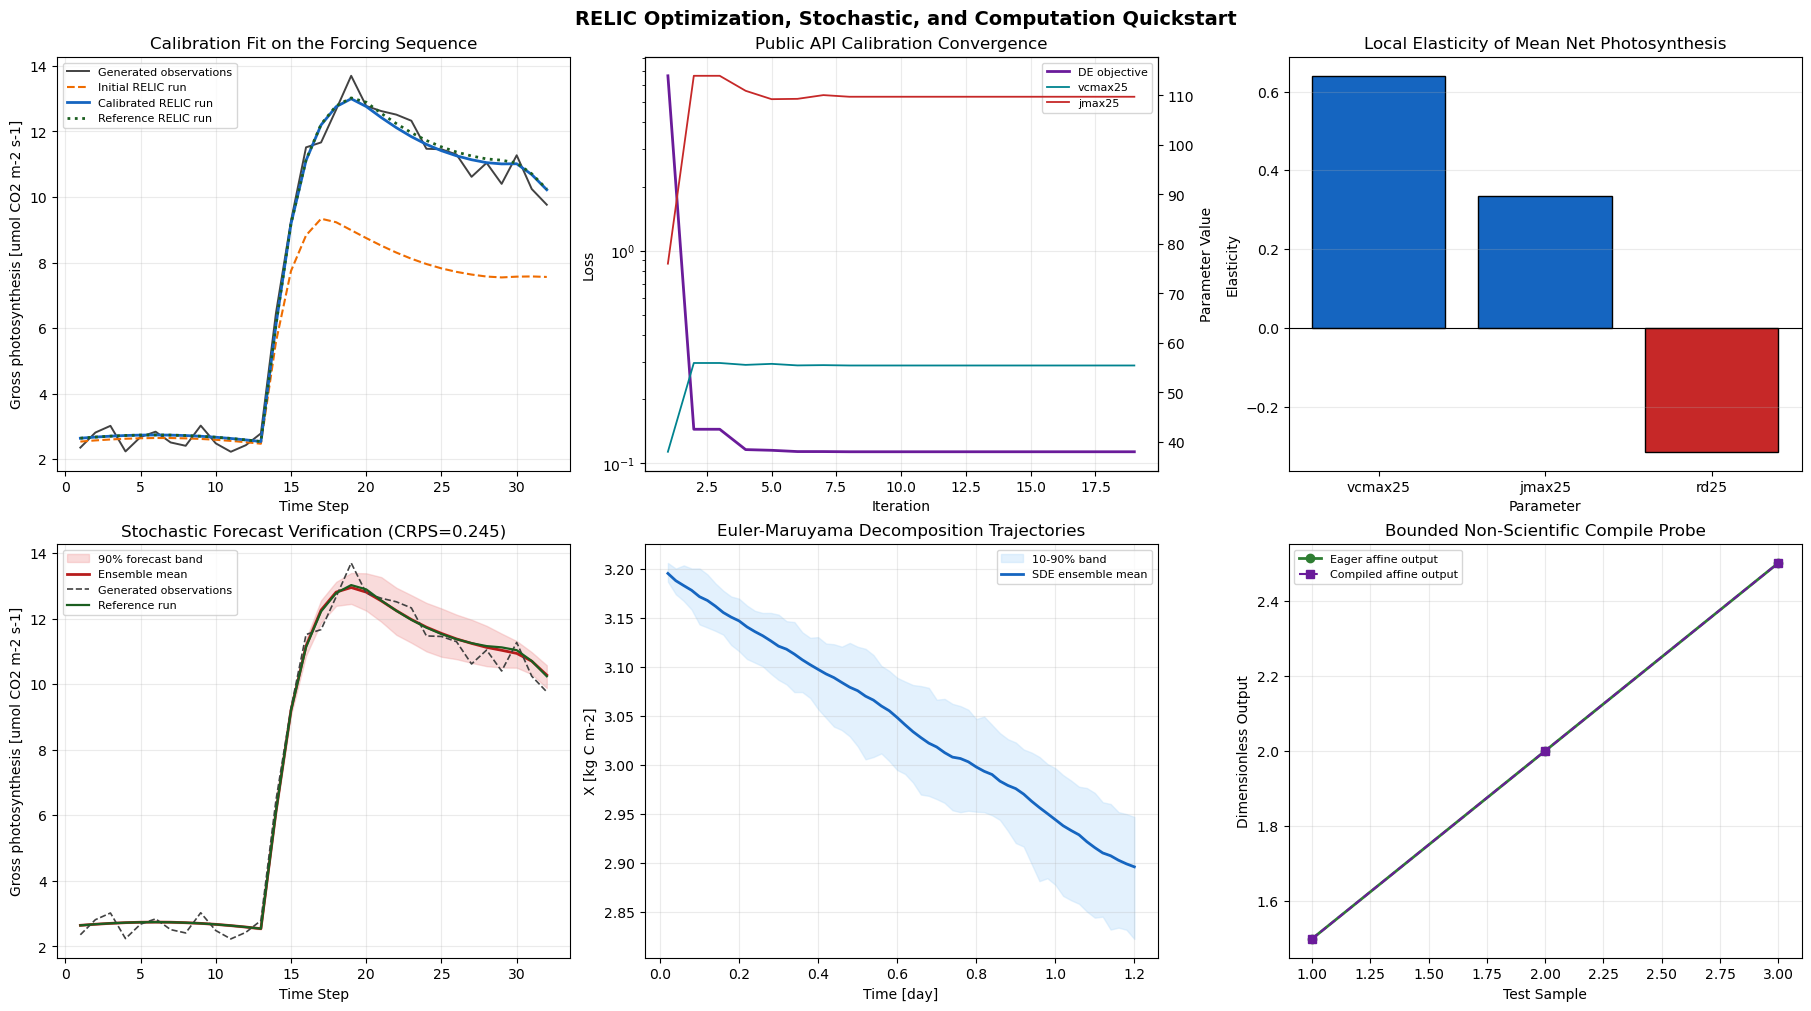

[OK] NB09 figures combine actual RELIC outputs with one explicitly bounded non-scientific compile probe.


In [8]:
from IPython.display import display
# References:
# - Actual outputs from FarquharPhotosynthesis, ParameterCalibrator, EnsembleRunner, and EulerMaruyamaSolver.
# Mathematical expression:
# - RMSE = sqrt(mean((y_hat - y_ref)^2))
# - q_low, q_high: empirical ensemble quantiles.
# Parameter meanings:
# - loss_history: calibration objective history.
# - ensemble_q05 and ensemble_q95: forecast uncertainty band.
# - local_sensitivity: normalized elasticity ranking.
# - runtime_output: bounded non-scientific compiled-probe output.

sde_paths = sde_solution['solution'].squeeze(-1)
sde_time = sde_solution['time'][1:].detach().cpu()
sde_mean = sde_paths[:, 1:].mean(dim=0).detach().cpu()
sde_q10 = torch.quantile(sde_paths[:, 1:], 0.10, dim=0).detach().cpu()
sde_q90 = torch.quantile(sde_paths[:, 1:], 0.90, dim=0).detach().cpu()

fig, axes = plt.subplots(2, 3, figsize=(18, 10), constrained_layout=True)
plot_index = list(range(1, int(gpp_truth.numel()) + 1))

ax = axes[0, 0]
ax.plot(plot_index, gpp_observed.tolist(), color='#424242', linewidth=1.4, label='Generated observations')
ax.plot(plot_index, initial_outputs['gross_photosynthesis'].tolist(), color='#ef6c00', linewidth=1.5, linestyle='--', label='Initial RELIC run')
ax.plot(plot_index, calibrated_gpp.tolist(), color='#1565c0', linewidth=2.0, label='Calibrated RELIC run')
ax.plot(plot_index, gpp_truth.tolist(), color='#1b5e20', linewidth=2.0, linestyle=':', label='Reference RELIC run')
ax.set_title('Calibration Fit on the Forcing Sequence')
ax.set_xlabel('Time Step')
ax.set_ylabel('Gross photosynthesis [umol CO2 m-2 s-1]')
ax.grid(True, alpha=0.25)
ax.legend(fontsize=8)

ax = axes[0, 1]
iteration_index = list(range(1, len(loss_history) + 1))
ax.plot(iteration_index, loss_history, color='#6a1b9a', linewidth=2.0, label='DE objective')
ax.set_yscale('log')
ax.set_title('Public API Calibration Convergence')
ax.set_xlabel('Iteration')
ax.set_ylabel('Loss')
ax.grid(True, alpha=0.25)
ax2 = ax.twinx()
ax2.plot(iteration_index, vcmax_history, color='#00838f', linewidth=1.3, label='vcmax25')
ax2.plot(iteration_index, jmax_history, color='#c62828', linewidth=1.3, label='jmax25')
ax2.set_ylabel('Parameter Value')
line_group_1, label_group_1 = ax.get_legend_handles_labels()
line_group_2, label_group_2 = ax2.get_legend_handles_labels()
ax.legend(line_group_1 + line_group_2, label_group_1 + label_group_2, fontsize=8, loc='upper right')

ax = axes[0, 2]
parameter_names = list(local_sensitivity.keys())
parameter_values = [local_sensitivity[name] for name in parameter_names]
bar_colors = ['#1565c0' if value >= 0.0 else '#c62828' for value in parameter_values]
ax.bar(parameter_names, parameter_values, color=bar_colors, edgecolor='black')
ax.axhline(0.0, color='black', linewidth=0.8)
ax.set_title('Local Elasticity of Mean Net Photosynthesis')
ax.set_xlabel('Parameter')
ax.set_ylabel('Elasticity')
ax.grid(True, alpha=0.25, axis='y')

ax = axes[1, 0]
ax.fill_between(plot_index, ensemble_q05.tolist(), ensemble_q95.tolist(), color='#ef9a9a', alpha=0.35, label='90% forecast band')
ax.plot(plot_index, ensemble_mean.tolist(), color='#b71c1c', linewidth=2.0, label='Ensemble mean')
ax.plot(plot_index, gpp_observed.tolist(), color='#424242', linewidth=1.2, linestyle='--', label='Generated observations')
ax.plot(plot_index, gpp_truth.tolist(), color='#1b5e20', linewidth=1.6, label='Reference run')
ax.set_title(f'Stochastic Forecast Verification (CRPS={float(crps_result.score):.3f})')
ax.set_xlabel('Time Step')
ax.set_ylabel('Gross photosynthesis [umol CO2 m-2 s-1]')
ax.grid(True, alpha=0.25)
ax.legend(fontsize=8)

ax = axes[1, 1]
ax.fill_between(sde_time.tolist(), sde_q10.tolist(), sde_q90.tolist(), color='#bbdefb', alpha=0.4, label='10-90% band')
ax.plot(sde_time.tolist(), sde_mean.tolist(), color='#1565c0', linewidth=2.0, label='SDE ensemble mean')
ax.set_title('Euler-Maruyama Decomposition Trajectories')
ax.set_xlabel('Time [day]')
ax.set_ylabel('X [kg C m-2]')
ax.grid(True, alpha=0.25)
ax.legend(fontsize=8)

ax = axes[1, 2]
input_index = [1, 2, 3]
ax.plot(input_index, reference_output.detach().cpu().tolist(), marker='o', color='#2e7d32', linewidth=2.0, label='Eager affine output')
ax.plot(input_index, runtime_output.detach().cpu().tolist(), marker='s', color='#6a1b9a', linewidth=1.5, linestyle='--', label='Compiled affine output')
ax.set_title('Bounded Non-Scientific Compile Probe')
ax.set_xlabel('Test Sample')
ax.set_ylabel('Dimensionless Output')
ax.grid(True, alpha=0.25)
ax.legend(fontsize=8)

fig.suptitle('RELIC Optimization, Stochastic, and Computation Quickstart', fontsize=14, fontweight='bold')
display(plt.gcf())
plt.close(plt.gcf())
print('[OK] NB09 figures combine actual RELIC outputs with one explicitly bounded non-scientific compile probe.')

## Summary

This notebook now plays a narrow and explicit role in the tutorial suite:
- Inspect the public optimization and stochastic API inventory
- Run derivative-free calibration through an explicit runner of a RELIC Functor
- Screen local parameter elasticities without repeating the heavier global UQ workflow
- Verify stochastic forecasts with CRPS using ensemble predictions from actual RELIC runs
- Demonstrate the computation API with an explicitly bounded non-scientific compile probe

For deeper workflows, continue with:
- **NB10** for multi-Functor composition
- **NB20** for detailed calibration, Sobol sensitivity, and uncertainty propagation
- **NB27** for data assimilation on top of ensemble model states